# Separating land-surface temperatures and energy fluxes

All110935finite pixels of Landsat9LC09_172039_20230421 and ERA5 forcing are reconstructed, including6genuinely bare pixels. The1625missing acquisition pixels are shown as image background, never selected using fit quality. Vegetation/optical properties and height are nominal assumptions, not independent measured truth. Historical GeoTIFF flux bands are never inverse inputs.

A single radiometric temperature constrains a fourth-power mixture:
$$T_r^4=f_vT_c^4+(1-f_v)T_s^4.$$
Here Tr/Tc/Ts are mixed/canopy/soil kelvin temperatures and fv is the directional vegetation fraction derived from NDVI-based leaf area and geometry. Component radiation and heat exchange satisfy
$$R_{n,c}=H_c+LE_c,\quad R_{n,s}=H_s+LE_s+G,\quad H_c=\rho c_p(T_c-T_{ac})/R_x,\quad H_s=\rho c_p(T_s-T_{ac})/R_s.$$
Rn is net radiation, H sensible heat, LE latent heat, G ground heat, all in W/m²; rho air density, cp heat capacity, Tac canopy-interface air temperature, Rx/Rs canopy/soil resistance. A series resistance network, Priestley-Taylor canopy constraint and atmospheric stability iteration close the inverse.

**Corrected reproduction:** the original solar-partition helper used1313.25instead of1013.25mb, logcos instead of logairmass, and a visible-beam term/incorrect water projection in NIR diffuse radiation. These fail independent published Weiss equations and optical-path checks. Only this forcing helper was corrected; the complete PT/OSEB inverse is preserved. Full corrected original+repeat preceded the local correction and were frozen with the same strict boundaries. Uncorrected source, its exact local parity and numerical-backend sensitivity remain separately labeled historical evidence. This is not an unchanged-source reproduction.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
# Maintainer figure export; robust before/after tasks/domain/task migration.
tasks_dir=next(p for p in root.parents if p.name=='tasks')
configured_export=os.environ.get('IMAGING_REVIEW_EXPORT_DIR') or os.environ.get('IMAGING_REVIEW_DIR')
review_export_dir=Path(configured_export) if configured_export else tasks_dir.parent.parent/'imaging-101-maintainer'/'benchmark_readiness_20261029'/'notebook_exports'/root.name
review_export_dir.mkdir(parents=True,exist_ok=True)
from src.solvers import reconstruct
from src.preprocessing import load_observations
from src.visualization import image_from_pixels,save_review_figure
from evaluation.judge import evaluate
started=time.perf_counter();fresh,diagnostics=reconstruct();elapsed=time.perf_counter()-started
report=evaluate(fresh);assert report['passed'],report
np.savez_compressed('notebooks/reference_outputs/fresh_measurements.npz',**fresh)
def read(path):
    with np.load(path,allow_pickle=False) as z:return {k:z[k] for k in z.files}
original=read('notebooks/reference_outputs/upstream_measurements.npz')
old_np2=read('notebooks/reference_outputs/historical_uncorrected_np2.npz')
old_np1=read('notebooks/reference_outputs/historical_uncorrected_np1.npz')
inputs=load_observations();index=inputs['pixel_index'];mask=diagnostics['canopy_mask']
print('Full fresh inverse seconds:',elapsed,'Python:',sys.executable)
print(json.dumps(report,indent=2))
print('Original/fresh full-output maximum absolute differences:',{k:float(np.max(abs(fresh[k]-original[k]))) for k in fresh})
print('Source corrected flags:',np.unique(original['flag'],return_counts=True))
print('Fresh flags:',np.unique(diagnostics['pt_flag'],return_counts=True),'bare:',diagnostics['soil_flag'])
print('Original/fresh alphaPT max difference:',np.max(abs(diagnostics['pt_alpha_PT']-original['alpha_PT'][0])))


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch12_20261029\astro_earth_physics\tasks\landsat_two_source_energy_partition\src\physics_model.py:278: RuntimeWarning: invalid value encountered in divide
  L_diff = np.asarray(np.fabs(L - L_old) / np.fabs(L_old), dtype=np.float32)


Full fresh inverse seconds: 8.5022107999539 Python: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "maximum_temperature_absolute_error": 0.0,
    "maximum_flux_absolute_error": 0.0,
    "maximum_radiometric_reprojection_K": 2.6349051267970935e-05,
    "maximum_energy_closure_W_m2": 5.336848380466108e-05
  },
  "thresholds": {
    "maximum_temperature_absolute_error": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "maximum_flux_absolute_error": {
      "comparison": "<=",
      "boundary": 0.1
    },
    "maximum_radiometric_reprojection_K": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "maximum_energy_closure_W_m2": {
      "comparison": "<=",
      "boundary": 0.005
    }
  },
  "errors": []
}
Original/fresh full-output maximum absolute differences: {'reconstruction': 0.0, 'soil_temperature': 0.0, 'canopy_temperature': 0.0, 'soil_heat_flux': 0.0, 'radiation':

## How the inverse closes

NDVI gives effective leaf area $F=-\log(1-\mathrm{clip}(\mathrm{NDVI}-0.05,0,1))/0.5$. Spectral canopy transfer separates net radiation. Start with $T_c=\min(T_r,T_a)$ and neutral stability. The canopy sensible-heat constraint is
$$H_c=R_{n,c}\left[1-\alpha f_g\frac{s}{s+\gamma}\right],$$
where alpha starts at1.26, fg is the assumed green fraction, s the saturation-vapour-pressure slope and gamma the psychrometric coefficient in the same pressure/temperature units. Series resistances and a quartic temperature correction recover Tc, after which exact fourth-power mixing recovers Ts. Update interface temperature, soil resistance and fluxes. Reduce alpha by0.1 if daytime soil LE is negative; at zero transpiration, the source dry branch reallocates G/H while preserving both budgets.

Atmospheric stability is updated through
$$L=-\frac{\rho c_p T_a u_\ast^3}{\kappa g[H+0.61T_a c_p LE/\lambda]},$$
where L is Monin-Obukhov length in m, friction velocity u* in m/s, von Karman constant kappa=0.41, gravity g=9.8m/s² and lambda latent heat in J/kg. Original wind/heat stability corrections update aerodynamic and component resistances. The original15-iteration cap,0.001relative-L threshold and2/3-cycle detector remain. Thus this computes latent fluxes and component temperatures from mixed radiance, rather than transforming previously measured fluxes.

## Observed mixture and reconstructed components

Images retain the full footprint. The canopy-temperature background additionally marks the6physically absent canopies, which have no declared Tc output. Total latent/sensible heat is inferred from local component budgets, not copied from historical maps.

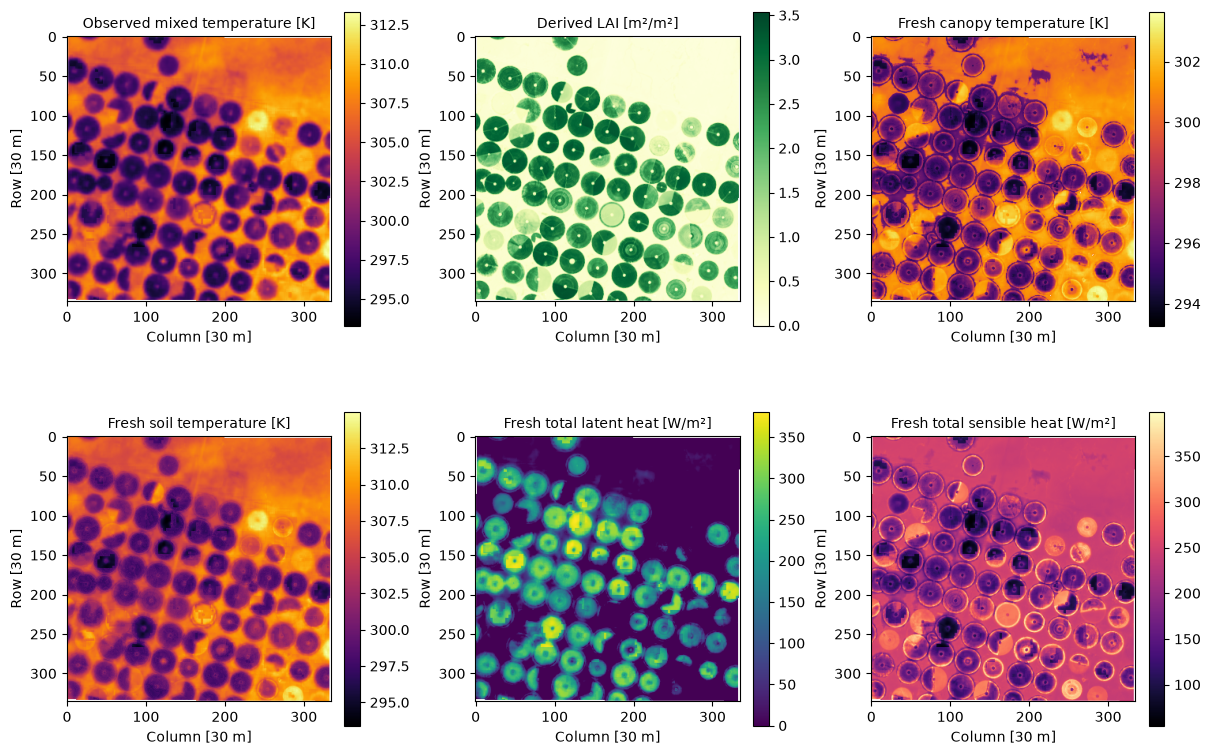

In [2]:
tc=np.full(len(index),np.nan);tc[mask]=fresh['canopy_temperature'][0]
le=fresh['reconstruction'][0,:,0]+fresh['reconstruction'][0,:,2]
h=fresh['reconstruction'][0,:,1]+fresh['reconstruction'][0,:,3]
items=[(inputs['radiometric_temperature'],'Observed mixed temperature [K]','inferno'),(diagnostics['LAI'],'Derived LAI [m²/m²]','YlGn'),(tc,'Fresh canopy temperature [K]','inferno'),(fresh['soil_temperature'][0],'Fresh soil temperature [K]','inferno'),(le,'Fresh total latent heat [W/m²]','viridis'),(h,'Fresh total sensible heat [W/m²]','magma')]
fig,axes=plt.subplots(2,3,figsize=(12,8),layout='constrained')
for ax,(values,title,cmap) in zip(axes.flat,items):
    im=ax.imshow(image_from_pixels(values,index),cmap=cmap,origin='upper');ax.set_title(title,fontsize=10);ax.set(xlabel='Column [30 m]',ylabel='Row [30 m]');fig.colorbar(im,ax=ax,shrink=.8)
save_review_figure(fig,str(review_export_dir/'pytseb_temperature_energy.png'));plt.show()


## Full component energy partition

All four declared turbulent fluxes are shown separately, together with G and net radiation. Zero latent heat in the daytime dry branch is the original constrained energy-balance solution. These zeros are computed and physically explained; no failed reconstruction was filled with zero.

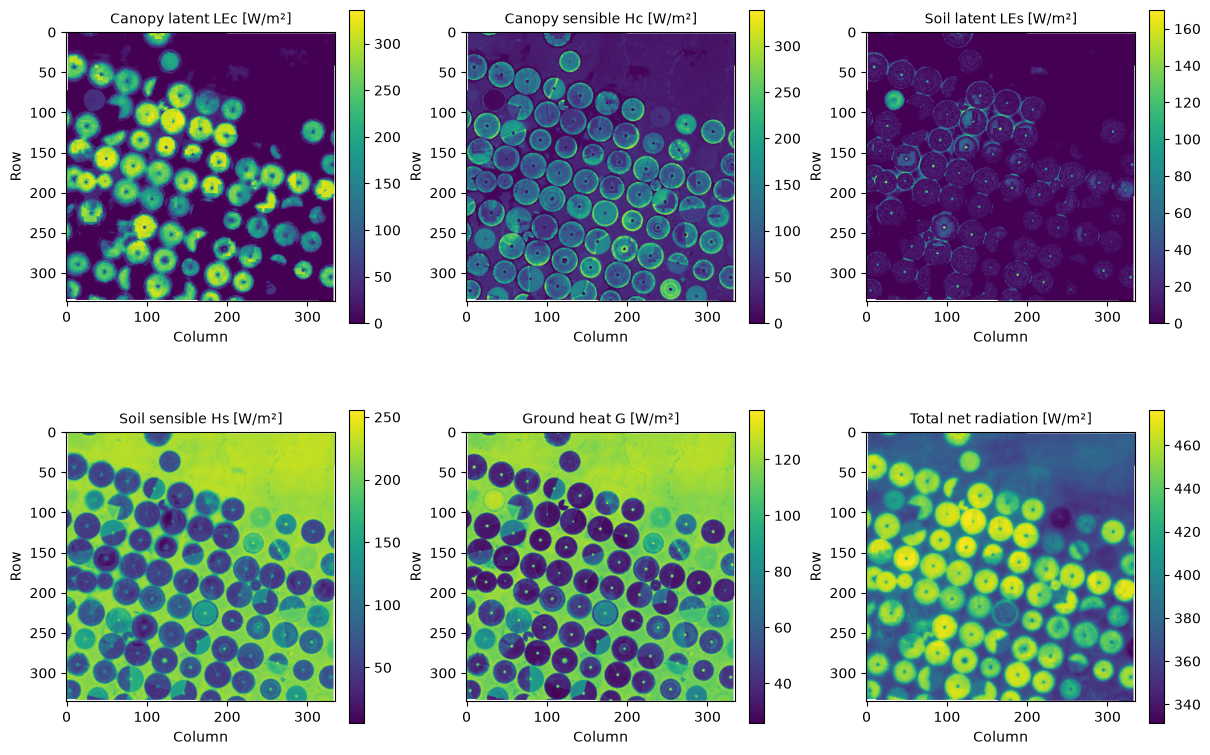

In [3]:
fig,axes=plt.subplots(2,3,figsize=(12,8),layout='constrained')
quantities=[(fresh['reconstruction'][0,:,j],label) for j,label in enumerate(['Canopy latent LEc','Canopy sensible Hc','Soil latent LEs','Soil sensible Hs'])]
quantities.extend([(fresh['soil_heat_flux'][0],'Ground heat G'),(fresh['radiation'][0].sum(axis=1),'Total net radiation')])
for ax,(values,title) in zip(axes.flat,quantities):
    im=ax.imshow(image_from_pixels(values,index),cmap='viridis',origin='upper');ax.set_title(title+' [W/m²]',fontsize=10);fig.colorbar(im,ax=ax,shrink=.8);ax.set(xlabel='Column',ylabel='Row')
save_review_figure(fig,str(review_export_dir/'pytseb_components.png'));plt.show()


## Actual assumption and implementation experiments

Run the full inverse again at nominal canopy heights0.27and0.33m. This is sensitivity to an assumed property, not measurement uncertainty. Compare the corrected forcing with the historical uncorrected source on the identical observations. Separately compare the two historical uncorrected original backends (NumPy1.26versus2.4), whose precision changes can affect rare stability-iteration paths. The corrected primary reference uses the matching NumPy2backend and is independently repeated; backend variation does not loosen its numerical threshold.

Full height experiment 0.27 finite pixels 110935 flags (array([0, 3, 5], dtype=int32), array([16155, 48551, 46223]))


Full height experiment 0.33 finite pixels 110935 flags (array([0, 3, 5], dtype=int32), array([12772, 46273, 51884]))
Corrected minus uncorrected original mean,RMS,maxabs: 0.9759973018624061 2.037335422966827 14.386810302734375
Height 0.27 minus 0.30 m mean,RMS,maxabs: 3.77073951748185 5.811756822806042 23.738143920898438
Height 0.33 minus 0.30 m mean,RMS,maxabs: -3.3717417612057323 5.403953394433898 21.90337371826172
Historical NumPy2 minus NumPy1 mean,RMS,maxabs: 4.9744266147745054e-05 0.04350422125829533 11.014179229736328
Correction complete quantity RMS/maxabs: {'reconstruction': [3.5495638987566824, 36.646087646484375], 'soil_temperature': [0.13442731372007466, 1.62750244140625], 'canopy_temperature': [0.1340854593220356, 0.7601318359375], 'soil_heat_flux': [0.9150597840722217, 8.984798431396484], 'radiation': [1.6887015083829358, 12.735801696777344]}
Historical backend complete quantity RMS/maxabs: {'reconstruction': [0.1031134732932588, 34.5457763671875], 'soil_temperature': [0.

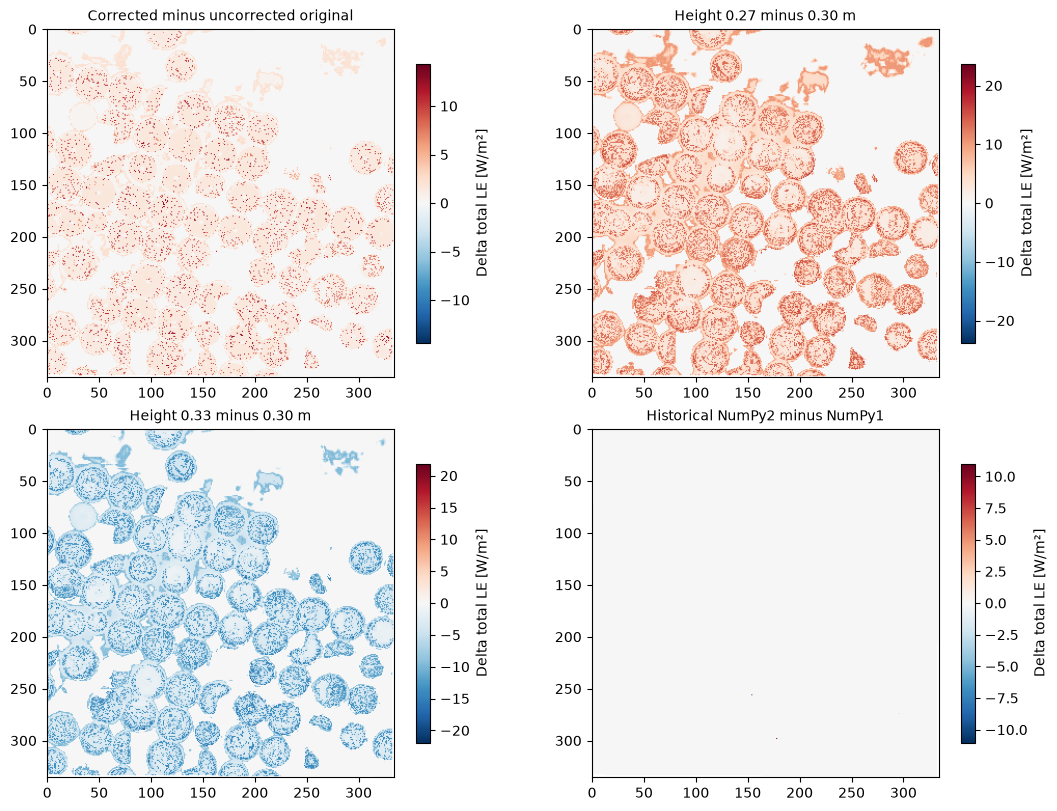

In [4]:
perturbed={}
for height in [.27,.33]:
    result,states=reconstruct(nominal_height=height);perturbed[height]=result
    print('Full height experiment',height,'finite pixels',result['soil_temperature'].shape[1],'flags',np.unique(states['pt_flag'],return_counts=True))
def total_le(result):return result['reconstruction'][0,:,0]+result['reconstruction'][0,:,2]
changes=[(total_le(fresh)-total_le(old_np2),'Corrected minus uncorrected original'),
         (total_le(perturbed[.27])-total_le(fresh),'Height 0.27 minus 0.30 m'),
         (total_le(perturbed[.33])-total_le(fresh),'Height 0.33 minus 0.30 m'),
         (total_le(old_np2)-total_le(old_np1),'Historical NumPy2 minus NumPy1')]
fig,axes=plt.subplots(2,2,figsize=(11,8),layout='constrained')
for ax,(delta,label) in zip(axes.flat,changes):
    extent=max(abs(delta.min()),abs(delta.max()),1e-9)
    im=ax.imshow(image_from_pixels(delta,index),cmap='RdBu_r',vmin=-extent,vmax=extent,origin='upper');ax.set_title(label,fontsize=10);fig.colorbar(im,ax=ax,label='Delta total LE [W/m²]',shrink=.8)
    print(label,'mean,RMS,maxabs:',float(np.mean(delta)),float(np.sqrt(np.mean(delta**2))),float(np.max(abs(delta))))
for label,first,second in [('Correction',fresh,old_np2),('Historical backend',old_np2,old_np1)]:
    print(label,'complete quantity RMS/maxabs:',{k:[float(np.sqrt(np.mean((first[k]-second[k])**2))),float(np.max(abs(first[k]-second[k])))] for k in fresh})
save_review_figure(fig,str(review_export_dir/'pytseb_sensitivity.png'));plt.show()


## Physical closure, stability and retained branches

The independent Judge uses fourth-power radiance reprojection and both component energy balances on every acquired pixel. The source infinite neutral initialization produces an inf/inf convergence warning before finite solutions; it is retained and recorded. All final quantities are finite. Heated daytime virtual sensible flux gives negative Monin-Obukhov length. No out-of-range or invalid output is hidden.

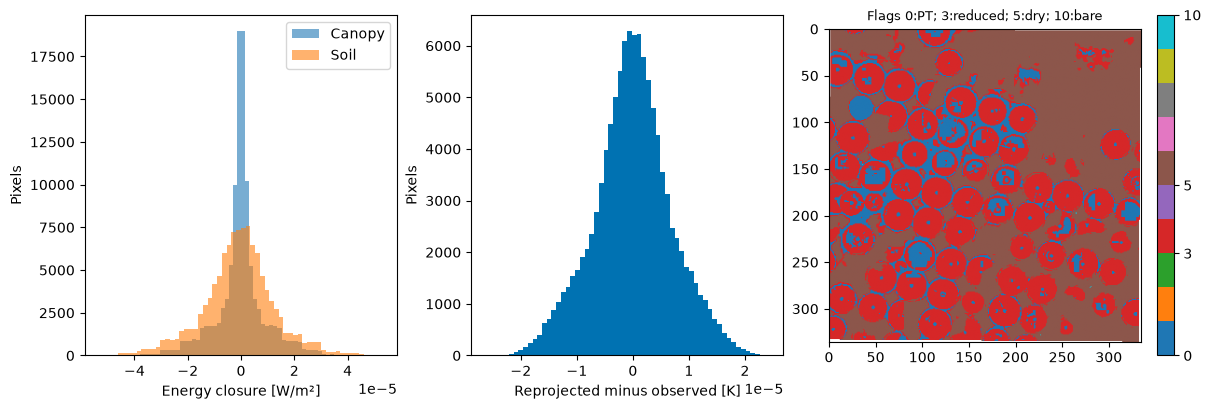

Conclusion: all pixels and physical identities pass; nominal properties and model assumptions limit physical accuracy without independent flux/component-temperature truth.


In [5]:
flux=fresh['reconstruction'][0];radiation=fresh['radiation'][0];g=fresh['soil_heat_flux'][0]
cc=radiation[:,0]+radiation[:,2]-flux[:,0]-flux[:,1]
cs=radiation[:,1]+radiation[:,3]-flux[:,2]-flux[:,3]-g
k=1/(1+1.774*(1+1.182)**(-.733));f=1-np.exp(-k*diagnostics['LAI'][mask].astype('float64'))
mixed=fresh['soil_temperature'][0].copy()
mixed[mask]=(f*fresh['canopy_temperature'][0]**4+(1-f)*fresh['soil_temperature'][0,mask]**4)**.25
residual=mixed-inputs['radiometric_temperature']
flag=np.empty(len(index));flag[mask]=diagnostics['pt_flag'];flag[~mask]=diagnostics['soil_flag']
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
axes[0].hist(cc,bins=60,alpha=.6,label='Canopy');axes[0].hist(cs,bins=60,alpha=.6,label='Soil');axes[0].set(xlabel='Energy closure [W/m²]',ylabel='Pixels');axes[0].legend()
axes[1].hist(residual,bins=60,color='#0072B2');axes[1].set(xlabel='Reprojected minus observed [K]',ylabel='Pixels')
im=axes[2].imshow(image_from_pixels(flag,index),cmap='tab10',vmin=0,vmax=10);axes[2].set_title('Flags 0:PT; 3:reduced; 5:dry; 10:bare',fontsize=9);fig.colorbar(im,ax=axes[2],ticks=[0,3,5,10])
save_review_figure(fig,str(review_export_dir/'pytseb_physics.png'));plt.show()
assert np.all(diagnostics['pt_L']<0) and np.all(diagnostics['soil_L']<0)
print('Conclusion: all pixels and physical identities pass; nominal properties and model assumptions limit physical accuracy without independent flux/component-temperature truth.')
